# 09 — Building blocks for the Qiskit addons: `qiskit-addon-utils`

[`qiskit-addon-utils`](https://qiskit.github.io/qiskit-addon-utils/) (version 0.4.0 here) is the companion package of the
Qiskit addons (MPF, OBP, AQC-Tensor, SQD, cutting, ...). It contains no algorithm of its own. It supplies the shared building
blocks of the addon workflows:

| submodule | contents |
|---|---|
| [`problem_generators`](https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.problem_generators.html) | `generate_xyz_hamiltonian` (XYZ, Heisenberg and Ising Hamiltonians on any coupling graph), `PauliOrderStrategy`, `generate_time_evolution_circuit` (Trotter circuits) |
| [`coloring`](https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.coloring.html) | `auto_color_edges`, `is_valid_edge_coloring`. An edge coloring defines which two-qubit gates can run in parallel. |
| [`slicing`](https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.slicing.html) | `slice_by_depth`, `slice_by_gate_types`, `slice_by_coloring`, `slice_by_barriers`, `combine_slices`, and the transpiler passes `CollectOpType`, `CollectOpSize`, `CollectOpColor` |
| [`exp_vals`](https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.exp_vals.html) | `get_measurement_bases`, `executor_expectation_values` (expectation values from raw bits, with twirling, PEC signs, post-selection and TREX), helpers to re-index observables |
| [`noise_management`](https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.noise_management.html) | `gamma_from_noisy_boxes` (PEC overhead from Pauli–Lindblad noise models), `trex_factors` (readout-error mitigation), post-selection with bit-flip checks (`bit_flip_checks`, `post_selection`) |

Abbreviations: **PEC** = probabilistic error cancellation. **TREX** = twirled readout error extinction. Both methods are described in the IBM Quantum guide [Error mitigation and suppression techniques](https://quantum.cloud.ibm.com/docs/en/guides/error-mitigation-and-suppression-techniques).

**Based on**

* How-to: [Use edge coloring to reduce the depth of quantum circuits](https://qiskit.github.io/qiskit-addon-utils/how_tos/color_device_edges_to_improve_depth.html) (Sections 1–2)
* How-to: [Slicing circuits using `qiskit_addon_utils.slicing`](https://qiskit.github.io/qiskit-addon-utils/how_tos/create_circuit_slices.html) (Section 4)
* How-to: [Postselection using bit-flip checks](https://qiskit.github.io/qiskit-addon-utils/how_tos/postselection_with_bit_flip_checks.html) (Section 7c)
* The API reference pages of each submodule (linked in the table above and in each section).
* Sections 3, 5, 6, 7a and 7b are our own examples, adapted from the API reference. The TREX and PEC background follows the IBM Quantum guide [Error mitigation and suppression techniques](https://quantum.cloud.ibm.com/docs/en/guides/error-mitigation-and-suppression-techniques).

Install line (from `qiskit.def`):

```bash
pip install qiskit-addon-utils
```

**Contents**

1. Problem generators: Hamiltonians on lines, rings, heavy-hex lattices and device subgraphs
2. Edge coloring and circuit depth
3. Time-evolution circuits, checked against exact evolution
4. Slicing circuits (depth, gate type, coloring, barriers) and recombining them
5. Input for the other addons: OBP, MPF (static and layer models) and AQC-Tensor
6. Expectation values from raw bits: measurement bases, twirling and TREX
7. Noise management: Pauli–Lindblad maps, the PEC overhead $\gamma$, a small PEC run, post-selection with bit-flip checks
8. Summary, notes on the installed version, and references

All cells run locally on simulators (statevector, Aer, and fake backends as transpilation targets).

In [1]:
import time as _time
_t_notebook = _time.time()
import warnings
from importlib.metadata import version

import numpy as np
import matplotlib.pyplot as plt
import rustworkx as rx
from rustworkx.visualization import mpl_draw
from scipy.linalg import expm

from qiskit import QuantumCircuit
from qiskit.transpiler import CouplingMap, PassManager, generate_preset_pass_manager
from qiskit.synthesis import LieTrotter, SuzukiTrotter
from qiskit.quantum_info import SparsePauliOp, Statevector, Operator, Pauli, PauliLindbladMap
from qiskit.primitives import StatevectorEstimator

import qiskit, qiskit_aer
print("qiskit", qiskit.__version__, "| qiskit-addon-utils", version("qiskit-addon-utils"),
      "| qiskit-addon-obp", version("qiskit-addon-obp"), "| qiskit-addon-mpf", version("qiskit-addon-mpf"),
      "| qiskit-aer", qiskit_aer.__version__)
estimator = StatevectorEstimator()

qiskit 2.5.2 | qiskit-addon-utils 0.4.0 | qiskit-addon-obp 0.3.0 | qiskit-addon-mpf 0.3.0 | qiskit-aer 0.17.2


## 1. Problem generators

`generate_xyz_hamiltonian(coupling, ...)` ([`problem_generators` API](https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.problem_generators.html)) builds an XYZ-type spin model on the edges $E$ and nodes $V$ of a coupling graph:

$$
\hat H=\sum_{(j,k)\in E}\left(J_x\,X_jX_k+J_y\,Y_jY_k+J_z\,Z_jZ_k\right)+\sum_{j\in V}\left(h_x X_j+h_y Y_j+h_z Z_j\right).
$$

* `coupling` can be a `CouplingMap`, a `rustworkx.PyGraph` or a `PyDiGraph`. The function ignores edge direction and merges duplicate
  (bidirectional) edges. A device coupling map can therefore be passed directly.
* `coupling_constants=(Jx, Jy, Jz)` and `ext_magnetic_field=(hx, hy, hz)` set the coefficients. Terms with zero coefficients are dropped.
  There is **no** hidden $-\tfrac12$ prefactor. Include any such factor in the numbers yourself.
* Qubit $i$ of the operator is node $i$ of the graph.

Special cases: Heisenberg $(J,J,J)$, XXZ $(J,J,\Delta)$, XY $(J,J,0)$, transverse-field Ising $(0,0,J)$ with $h=(h_x,0,0)$.

In [2]:
from qiskit_addon_utils.problem_generators import (
    PauliOrderStrategy, generate_time_evolution_circuit, generate_xyz_hamiltonian)
from qiskit_addon_utils.coloring import auto_color_edges, is_valid_edge_coloring

line4 = CouplingMap.from_line(4)            # bidirectional: 6 directed edges, 3 physical bonds
print("directed edges in CouplingMap.from_line(4):", line4.get_edges())

H_heis = generate_xyz_hamiltonian(line4, coupling_constants=(1.0, 1.0, 1.0))
H_tfim = generate_xyz_hamiltonian(line4, coupling_constants=(0.0, 0.0, -1.0), ext_magnetic_field=(-0.5, 0.0, 0.0))
print("\nHeisenberg chain (3 bonds x 3 terms):\n", H_heis)
print("\nTransverse-field Ising chain:\n", H_tfim)

# same model from a rustworkx graph (a 4-cycle) instead of a CouplingMap
g = rx.PyGraph(); g.add_nodes_from(range(4)); g.add_edges_from_no_data([(0, 1), (1, 2), (2, 3), (3, 0)])
print("\nXY model on a 4-cycle given as rx.PyGraph:", generate_xyz_hamiltonian(g, coupling_constants=(1, 1, 0)).paulis)

directed edges in CouplingMap.from_line(4): EdgeList[(0, 1), (1, 0), (1, 2), (2, 1), (2, 3), (3, 2)]

Heisenberg chain (3 bonds x 3 terms):
 SparsePauliOp(['IXXI', 'IYYI', 'IZZI', 'IIXX', 'IIYY', 'IIZZ', 'XXII', 'YYII', 'ZZII'],
              coeffs=[1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j])

Transverse-field Ising chain:
 SparsePauliOp(['IZZI', 'IIZZ', 'ZZII', 'IIIX', 'IIXI', 'IXII', 'XIII'],
              coeffs=[-1. +0.j, -1. +0.j, -1. +0.j, -0.5+0.j, -0.5+0.j, -0.5+0.j, -0.5+0.j])

XY model on a 4-cycle given as rx.PyGraph: ['IIXX', 'IIYY', 'XXII', 'YYII', 'XIIX', 'YIIY', 'IXXI', 'IYYI']


### Term order: `PauliOrderStrategy`

The *order* of the terms does not change $\hat H$. The product-formula synthesis keeps this order, however, so the order fixes
the gate order and the depth of the Trotter circuit. The edges are first grouped by their **edge color** (Section 2). Then:

* `ColorThenInteraction` (default): for each colored edge, emit $XX, YY, ZZ$ on that edge.
* `InteractionThenColor`: all $XX$ terms (by color), then all $YY$ terms, then all $ZZ$ terms.
* `InteractionThenColorZigZag`: like `InteractionThenColor`, but the color order is reversed for every second interaction
  ($XX$ on colors 0→1, $YY$ on colors 1→0, ...). Neighbouring layers then share a color, and a symmetric (second-order)
  formula can merge them.

An explicit `coloring={edge: color}` replaces the automatic coloring.

In [3]:
for strat in PauliOrderStrategy:
    H = generate_xyz_hamiltonian(line4, coupling_constants=(1.0, 1.0, 0.0), pauli_order_strategy=strat)
    print(f"{strat.name:28s}", [p.to_label() for p in H.paulis])

custom = {(0, 1): 1, (1, 2): 0, (2, 3): 1}   # put bond (1,2) first
H = generate_xyz_hamiltonian(line4, coupling_constants=(1.0, 0.0, 0.0), coloring=custom)
print("custom coloring             ", [p.to_label() for p in H.paulis])

ColorThenInteraction         ['IXXI', 'IYYI', 'IIXX', 'IIYY', 'XXII', 'YYII']
InteractionThenColor         ['IXXI', 'IIXX', 'XXII', 'IYYI', 'IIYY', 'YYII']
InteractionThenColorZigZag   ['IXXI', 'IIXX', 'XXII', 'YYII', 'IIYY', 'IYYI']
custom coloring              ['IXXI', 'IIXX', 'XXII']


### Lattices: line, ring, heavy-hex, and a device subgraph

Any coupling map works: `CouplingMap.from_line`, `from_ring`, `from_grid`, `from_heavy_hex`, `from_heavy_square`, or a device coupling map.
Below we build the Hamiltonian on four graphs. Each drawing shows the edges colored by `auto_color_edges`.
The fourth graph is a subgraph of the 127-qubit `FakeSherbrooke` backend (an Eagle device with a heavy-hex lattice). It contains physical
qubits 0–13, 14 and 18. We extract it with `CouplingMap.reduce`.

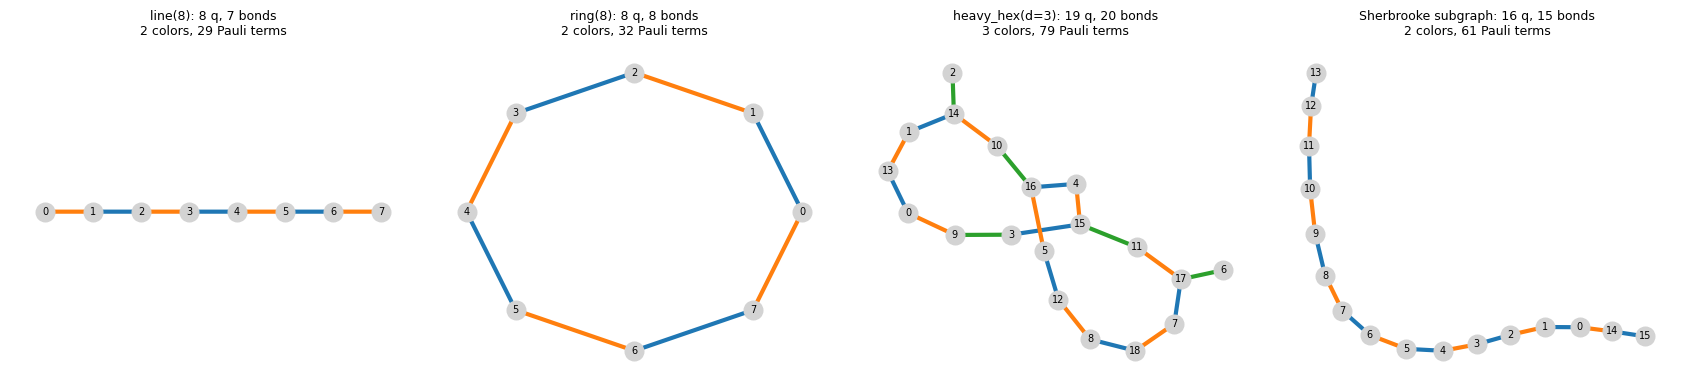

In [4]:
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke
backend = FakeSherbrooke()
dev_qubits = list(range(14)) + [14, 18]           # top row of the heavy-hex lattice + two bridge qubits
dev_sub = backend.coupling_map.reduce(dev_qubits)  # re-indexed 0..15

graphs = {
    "line(8)": CouplingMap.from_line(8),
    "ring(8)": CouplingMap.from_ring(8),
    "heavy_hex(d=3)": CouplingMap.from_heavy_hex(3),
    "Sherbrooke subgraph": dev_sub,
}
palette = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown", "tab:pink"]

def undirected(cmap):
    return cmap.graph.to_undirected(multigraph=False)

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (name, cmap) in zip(axes, graphs.items()):
    G = undirected(cmap)
    coloring = auto_color_edges(G.edge_list())
    H = generate_xyz_hamiltonian(cmap, coupling_constants=(1, 1, 1), ext_magnetic_field=(0, 0, 0.5))
    colors = [palette[coloring.get((a, b), coloring.get((b, a)))] for a, b in G.edge_list()]
    pos = rx.spring_layout(G, seed=3) if "heavy" in name else (
          rx.circular_layout(G) if "ring" in name else rx.spring_layout(G, seed=1))
    if name.startswith("line"):
        pos = {i: (i, 0) for i in G.node_indices()}
    mpl_draw(G, pos=pos, ax=ax, with_labels=True, edge_color=colors, width=3, node_size=180, font_size=7,
             node_color="lightgrey")
    ax.set_title(f"{name}: {G.num_nodes()} q, {G.num_edges()} bonds\n"
                 f"{len(set(coloring.values()))} colors, {H.size} Pauli terms", fontsize=9)
plt.tight_layout(); plt.show()

Look at the color counts. `auto_color_edges` uses the **greedy** edge coloring of rustworkx. With a clean *undirected* edge list,
it finds 2 colors for the line and the even ring, and 3 colors for the heavy-hex patch. Three is optimal for maximum degree 3.
The greedy result depends on the input edge list, however. The next section shows a simple way to get a bad result.

## 2. Edge coloring and circuit depth

An **edge coloring** assigns a color to each bond so that no two bonds of the same color share a qubit (how-to: [Use edge coloring to reduce the depth of quantum circuits](https://qiskit.github.io/qiskit-addon-utils/how_tos/color_device_edges_to_improve_depth.html); [`coloring` API](https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.coloring.html)). All two-qubit gates of
one color can then run in the same layer. With the default `ColorThenInteraction` order, one Trotter step of an XYZ model
has a two-qubit depth of $3\times(\text{number of colors})$. Fewer colors give a shallower circuit.

* `auto_color_edges(edges)` returns a greedy coloring, `{(a, b): color}`.
* `is_valid_edge_coloring(coloring)` checks that the coloring is proper (no shared qubits within a color).
* rustworkx also has `graph_misra_gries_edge_color` (at most $\Delta+1$ colors, where $\Delta$ is the maximum degree) and
  `graph_bipartite_edge_color` (exactly $\Delta$ colors on bipartite graphs, by König's theorem). Heavy-hex lattices are bipartite.

> **Pitfall.** `auto_color_edges` does **not** merge `(a, b)` with `(b, a)`. `CouplingMap.get_edges()` of a bidirectional coupling map
> lists every bond twice, so each bond gets two colors. If this coloring goes to `generate_xyz_hamiltonian(..., coloring=...)`,
> **each bond's terms appear twice** (this doubles $J$). Without `coloring=`, `generate_xyz_hamiltonian` makes the graph undirected
> first, so this problem does not occur.

In [5]:
def coloring_from_rx(G, color_by_edge_index):
    return {G.get_edge_endpoints_by_index(i): c for i, c in color_by_edge_index.items()}

hh = CouplingMap.from_heavy_hex(3)
G = undirected(hh)
colorings = {
    "auto_color_edges (greedy)": auto_color_edges(G.edge_list()),
    "Misra-Gries": coloring_from_rx(G, rx.graph_misra_gries_edge_color(G)),
    "bipartite (König)": coloring_from_rx(G, rx.graph_bipartite_edge_color(G)),
}
print("max degree:", max(G.degree(n) for n in G.node_indices()))
depth2q = lambda qc: qc.depth(lambda ins: ins.operation.num_qubits == 2)
for name, col in colorings.items():
    H = generate_xyz_hamiltonian(hh, coupling_constants=(1, 1, 1), coloring=col)
    qc = generate_time_evolution_circuit(H, time=0.1)        # one Lie-Trotter step
    print(f"{name:27s} colors={len(set(col.values()))}  valid={is_valid_edge_coloring(col)}  "
          f"2q depth of one step={depth2q(qc):3d}  total depth={qc.depth()}")

bad = dict(colorings["bipartite (König)"]); e0, e1 = [e for e in bad if 1 in e][:2]; bad[e1] = bad[e0]
print("\ncoloring with two same-colored bonds on qubit 1 -> valid:", is_valid_edge_coloring(bad))

directed = auto_color_edges(hh.get_edges())          # bidirectional edge list: (a,b) and (b,a) both present
H_ok = generate_xyz_hamiltonian(hh, coupling_constants=(1, 1, 1))
H_dup = generate_xyz_hamiltonian(hh, coupling_constants=(1, 1, 1), coloring=directed)
print(f"\nauto_color_edges(hh.get_edges()): {len(directed)} 'edges' for {G.num_edges()} bonds, "
      f"{len(set(directed.values()))} colors")
print(f"terms: default H {H_ok.size}, with that coloring {H_dup.size}; "
      f"equal after simplify? {H_dup.simplify().equiv(H_ok.simplify())} (bonds counted twice)")

max degree: 3


auto_color_edges (greedy)   colors=3  valid=True  2q depth of one step=  9  total depth=9
Misra-Gries                 colors=4  valid=True  2q depth of one step= 12  total depth=12
bipartite (König)           colors=3  valid=True  2q depth of one step=  9  total depth=9

coloring with two same-colored bonds on qubit 1 -> valid: False

auto_color_edges(hh.get_edges()): 40 'edges' for 20 bonds, 6 colors
terms: default H 60, with that coloring 120; equal after simplify? False (bonds counted twice)


## 3. Time-evolution circuits

`generate_time_evolution_circuit(H, synthesis=..., time=t)` ([`problem_generators` API](https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.problem_generators.html)) wraps $e^{-i\hat H t}$ in a `PauliEvolutionGate` with the
given `EvolutionSynthesis` and decomposes it once. Without `synthesis`, the default is first-order Lie–Trotter with one step.

| synthesis | formula | global error |
|---|---|---|
| `LieTrotter(reps=k)` | $\big[\prod_a e^{-iH_a t/k}\big]^k$ | $O(t^2/k)$ |
| `SuzukiTrotter(order=2, reps=k)` | symmetric $\prod_a e^{-iH_a t/2k}\prod_{a}^{\leftarrow} e^{-iH_a t/2k}$ | $O(t^3/k^2)$ |
| `SuzukiTrotter(order=4, reps=k)` | fourth-order Suzuki formula, about 5× the cost per step | $O(t^5/k^4)$ |

The gate is decomposed, so the returned circuit contains the actual Trotter gates (`rxx`, `ryy`, `rzz`, `rx`, `rz`, ...).
A simulation of this circuit therefore shows the **Trotter error**. In contrast, `Statevector` and `StatevectorEstimator` simulate
an undecomposed `PauliEvolutionGate` *exactly*.

The model is an XXZ chain with a transverse field on $N=8$ qubits,
$\hat H=\sum_j (X_jX_{j+1}+Y_jY_{j+1}+0.5\,Z_jZ_{j+1})+0.4\sum_j X_j$. The initial state is the Néel state $|01010101\rangle$.

Lie-Trotter, 1 step: {'rx': 4, 'rxx': 3, 'ryy': 3, 'rzz': 3} | depth 7
Suzuki-2,    1 step: {'rx': 7, 'rxx': 6, 'ryy': 6, 'rzz': 6} | depth 14


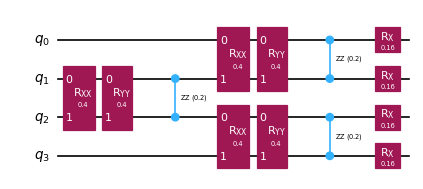

In [6]:
small = generate_xyz_hamiltonian(CouplingMap.from_line(4), coupling_constants=(1.0, 1.0, 0.5),
                                 ext_magnetic_field=(0.4, 0.0, 0.0))
c_lt = generate_time_evolution_circuit(small, synthesis=LieTrotter(reps=1), time=0.2)
c_st = generate_time_evolution_circuit(small, synthesis=SuzukiTrotter(order=2, reps=1), time=0.2)
print("Lie-Trotter, 1 step:", dict(c_lt.count_ops()), "| depth", c_lt.depth())
print("Suzuki-2,    1 step:", dict(c_st.count_ops()), "| depth", c_st.depth())
c_lt.draw("mpl", fold=-1, scale=0.6)

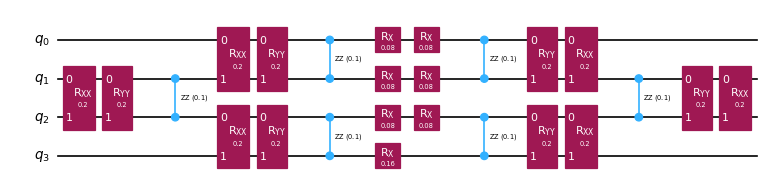

In [7]:
c_st.draw("mpl", fold=-1, scale=0.6)

With the default `ColorThenInteraction` order, the mirrored half of the second-order formula starts with the same block that ends the
first half. These two blocks merge, so the gate count is less than double. The next cell compares the unitaries directly.
The Trotter circuit is *not* the exact propagator, but it converges to it as `reps` grows.

In [8]:
U_exact = expm(-1j * 0.2 * small.to_matrix())
for k in (1, 2, 4, 8):
    U_k = Operator(generate_time_evolution_circuit(small, synthesis=LieTrotter(reps=k), time=0.2)).data
    print(f"Lie-Trotter reps={k}: ||U_k - exp(-iHt)||_2 = {np.linalg.norm(U_k - U_exact, 2):.2e}")

Lie-Trotter reps=1: ||U_k - exp(-iHt)||_2 = 1.88e-01
Lie-Trotter reps=2: ||U_k - exp(-iHt)||_2 = 9.35e-02
Lie-Trotter reps=4: ||U_k - exp(-iHt)||_2 = 4.67e-02
Lie-Trotter reps=8: ||U_k - exp(-iHt)||_2 = 2.33e-02


### Comparison with exact evolution

We compute two observables with `StatevectorEstimator` on the Trotter circuits:

* the staggered magnetization $M_s=\frac1N\sum_j(-1)^jZ_j$;
* the bond correlator $\langle Z_3Z_4\rangle$.

The reference is the exact state $e^{-i\hat Ht}|\psi_0\rangle$ from diagonalization of $\hat H$.

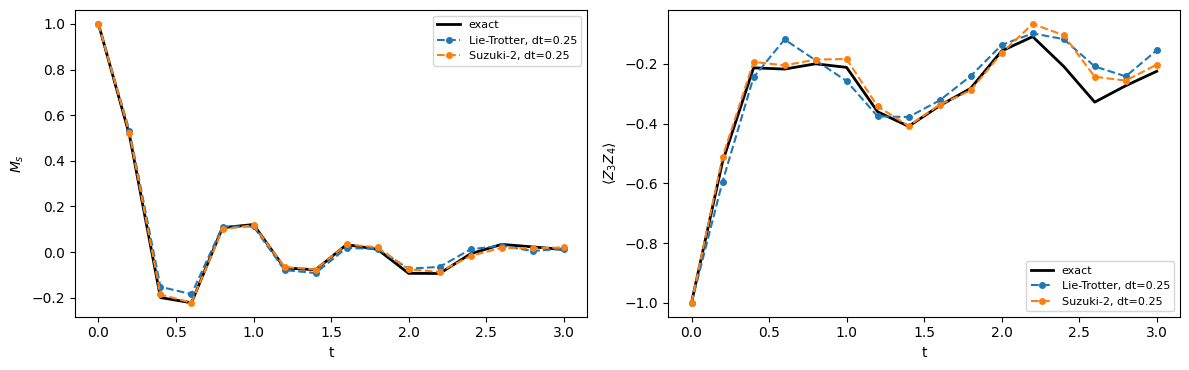

Lie-Trotter, dt=0.25   max |error| in M_s: 4.70e-02
Suzuki-2, dt=0.25      max |error| in M_s: 1.75e-02


In [9]:
N = 8
chain = CouplingMap.from_line(N)
H = generate_xyz_hamiltonian(chain, coupling_constants=(1.0, 1.0, 0.5), ext_magnetic_field=(0.4, 0.0, 0.0))
Ms = SparsePauliOp.from_sparse_list([("Z", [j], (-1) ** j / N) for j in range(N)], N)
ZZ34 = SparsePauliOp.from_sparse_list([("ZZ", [3, 4], 1.0)], N)

neel = QuantumCircuit(N)
neel.x(range(1, N, 2))                              # |01010101>, qubit 0 = site 0
psi0 = Statevector(neel).data
Hm, Msm, ZZm = H.to_matrix(sparse=False), Ms.to_matrix(), ZZ34.to_matrix()
evals, evecs = np.linalg.eigh(Hm)
def exact(t):
    psi = evecs @ (np.exp(-1j * evals * t) * (evecs.conj().T @ psi0))
    return np.real(np.vdot(psi, Msm @ psi)), np.real(np.vdot(psi, ZZm @ psi))

def trotter_circuit(t, synthesis):
    return neel.compose(generate_time_evolution_circuit(H, synthesis=synthesis, time=t))

times = np.linspace(0, 3, 16)
ex = np.array([exact(t) for t in times])
results = {}
for label, synth_of_t in {
    "Lie-Trotter, dt=0.25": lambda t: LieTrotter(reps=max(1, int(np.ceil(t / 0.25)))),
    "Suzuki-2, dt=0.25":    lambda t: SuzukiTrotter(order=2, reps=max(1, int(np.ceil(t / 0.25)))),
}.items():
    pubs = [(trotter_circuit(t, synth_of_t(t)), [Ms, ZZ34]) for t in times]
    results[label] = np.array([r.data.evs for r in estimator.run(pubs).result()])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for i, name in enumerate([r"$M_s$", r"$\langle Z_3Z_4\rangle$"]):
    ax[i].plot(times, ex[:, i], "k-", lw=2, label="exact")
    for label, r in results.items():
        ax[i].plot(times, r[:, i], "o--", ms=4, label=label)
    ax[i].set_xlabel("t"); ax[i].set_ylabel(name); ax[i].legend(fontsize=8)
plt.tight_layout(); plt.show()
for label, r in results.items():
    print(f"{label:22s} max |error| in M_s: {np.abs(r[:, 0] - ex[:, 0]).max():.2e}")

Lie-Trotter (order 1)  state-error slope (last 3 points): -1.02
Suzuki (order 2)       state-error slope (last 3 points): -2.01
Suzuki (order 4)       state-error slope (last 3 points): -3.94


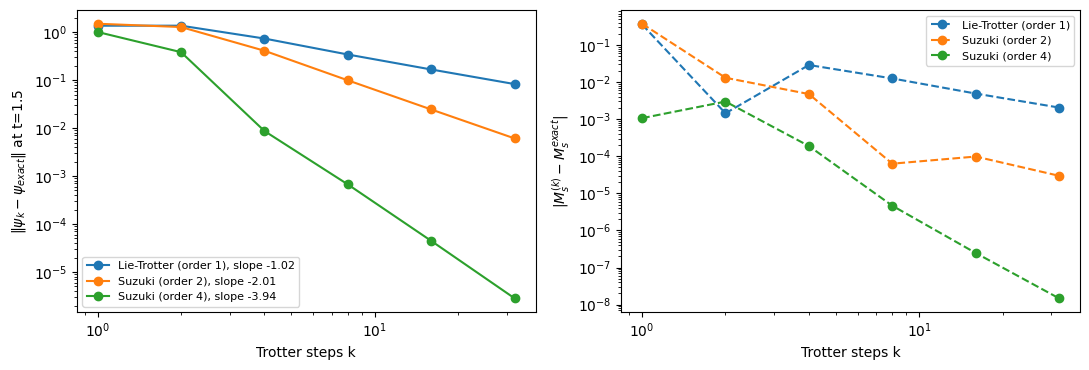

In [10]:
# Convergence with the number of steps at fixed t = 1.5.
# A single expectation value can cross the exact curve (its error is not monotone in k), so we measure
# the *state* error ||psi_k - psi_exact|| (a bound on all observables) together with |M_s error|.
t = 1.5
ks = np.array([1, 2, 4, 8, 16, 32])
psi_ex = evecs @ (np.exp(-1j * evals * t) * (evecs.conj().T @ psi0))
exact_ms = exact(t)[0]
state_err, ms_err = {}, {}
for label, mk in {"Lie-Trotter (order 1)": lambda k: LieTrotter(reps=k),
                  "Suzuki (order 2)": lambda k: SuzukiTrotter(order=2, reps=k),
                  "Suzuki (order 4)": lambda k: SuzukiTrotter(order=4, reps=k)}.items():
    circs = [trotter_circuit(t, mk(k)) for k in ks]
    state_err[label] = np.array([np.linalg.norm(Statevector(c).data - psi_ex) for c in circs])
    ms_err[label] = np.abs(np.array([r.data.evs for r in estimator.run([(c, Ms) for c in circs]).result()]) - exact_ms)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for label in state_err:
    slope = np.polyfit(np.log(ks[-3:]), np.log(state_err[label][-3:]), 1)[0]
    ax[0].loglog(ks, state_err[label], "o-", label=f"{label}, slope {slope:.2f}")
    ax[1].loglog(ks, ms_err[label], "o--", label=label)
    print(f"{label:22s} state-error slope (last 3 points): {slope:.2f}")
ax[0].set_xlabel("Trotter steps k"); ax[0].set_ylabel(r"$\|\psi_k-\psi_{exact}\|$ at t=1.5"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("Trotter steps k"); ax[1].set_ylabel(r"$|M_s^{(k)} - M_s^{exact}|$"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

The state error falls as $k^{-p}$. The fitted slopes (printed above) are close to the formula orders $p=1,2,4$. The error of the single
observable $M_s$ (right panel) is bounded by the state error. It is not monotone in $k$, because it can change sign. The agreement at large $k$
shows that the circuit, the qubit order and the observable conventions match the exact reference.

### Mapping onto a device layout without SWAPs (fake backend target)

If the Hamiltonian is built on a device subgraph, the transpiler only needs the matching `initial_layout`. It inserts no SWAP gates,
and each `rxx`/`ryy`/`rzz` becomes a fixed number of native ECR gates (2 here).

In [11]:
H_dev = generate_xyz_hamiltonian(dev_sub, coupling_constants=(1.0, 1.0, 0.5), ext_magnetic_field=(0.4, 0, 0))
qc_dev = generate_time_evolution_circuit(H_dev, synthesis=LieTrotter(reps=2), time=0.5)
pm = generate_preset_pass_manager(optimization_level=1, backend=backend, initial_layout=dev_qubits, seed_transpiler=1)
isa = pm.run(qc_dev)
n2q_logical = sum(1 for ins in qc_dev.data if ins.operation.num_qubits == 2)
print(f"{qc_dev.num_qubits} logical qubits, {n2q_logical} two-qubit rotations")
print("ISA ops:", dict(isa.count_ops()))
print("ECRs per two-qubit rotation:", isa.count_ops().get("ecr", 0) / n2q_logical,
      "| physical qubits used:", sorted(isa.layout.final_index_layout()))

16 logical qubits, 90 two-qubit rotations
ISA ops: {'rz': 495, 'sx': 336, 'ecr': 180, 'x': 62}
ECRs per two-qubit rotation: 2.0 | physical qubits used: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 18]


## 4. Slicing circuits

Several addons treat a circuit as a sequence of **slices**. A slice is a time-wise partition that covers all qubits (how-to: [Slicing circuits](https://qiskit.github.io/qiskit-addon-utils/how_tos/create_circuit_slices.html); [`slicing` API](https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.slicing.html)).
OBP backpropagates the observable slice by slice. The MPF layer models need one layer per slice. Noise learning works per layer.
The `slicing` module has four slicing strategies and one function to recombine the slices:

| function | one slice = |
|---|---|
| `slice_by_depth(circ, max_slice_depth)` | up to `max_slice_depth` consecutive DAG layers |
| `slice_by_gate_types(circ)` | a depth-1 block of a single gate type (for example, all `rzz` gates that can run together) |
| `slice_by_coloring(circ, coloring)` | all two-qubit gates on bonds of one color (single-qubit gates are collected separately) |
| `slice_by_barriers(circ)` | the region between two **full-width** barriers (partial barriers stay as normal operations) |
| `combine_slices(slices, include_barriers=False)` | concatenation of the slices, optionally with barriers between them |

The example circuit is two Lie–Trotter steps of the XXZ model with a field, on 4 qubits.

depth 14 {'rx': 8, 'rxx': 6, 'ryy': 6, 'rzz': 6}
slice_by_depth(3): 5 slices, depths [3, 3, 3, 3, 2]


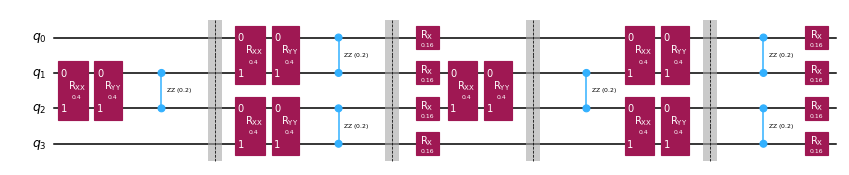

In [12]:
from qiskit_addon_utils.slicing import (combine_slices, slice_by_barriers, slice_by_coloring,
                                        slice_by_depth, slice_by_gate_types)

H4 = generate_xyz_hamiltonian(CouplingMap.from_line(4), coupling_constants=(1.0, 1.0, 0.5),
                              ext_magnetic_field=(0.4, 0, 0))
circ = generate_time_evolution_circuit(H4, synthesis=LieTrotter(reps=2), time=0.4)
print("depth", circ.depth(), dict(circ.count_ops()))

def show_slices(slices, title, ncols=6):
    nrows = int(np.ceil(len(slices) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.6 * ncols, 2.3 * nrows))
    for i, ax in enumerate(np.atleast_1d(axes).ravel()):
        ax.axis("off")
        if i < len(slices):
            slices[i].draw("mpl", ax=ax, scale=0.45, idle_wires=True)
            ax.set_title(f"slice {i}: " + ",".join(slices[i].count_ops()), fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

by_depth = slice_by_depth(circ, max_slice_depth=3)
print("slice_by_depth(3):", len(by_depth), "slices, depths", [s.depth() for s in by_depth])
combine_slices(by_depth, include_barriers=True).draw("mpl", fold=-1, scale=0.55)

slice_by_gate_types: 14 slices, all depth 1: True


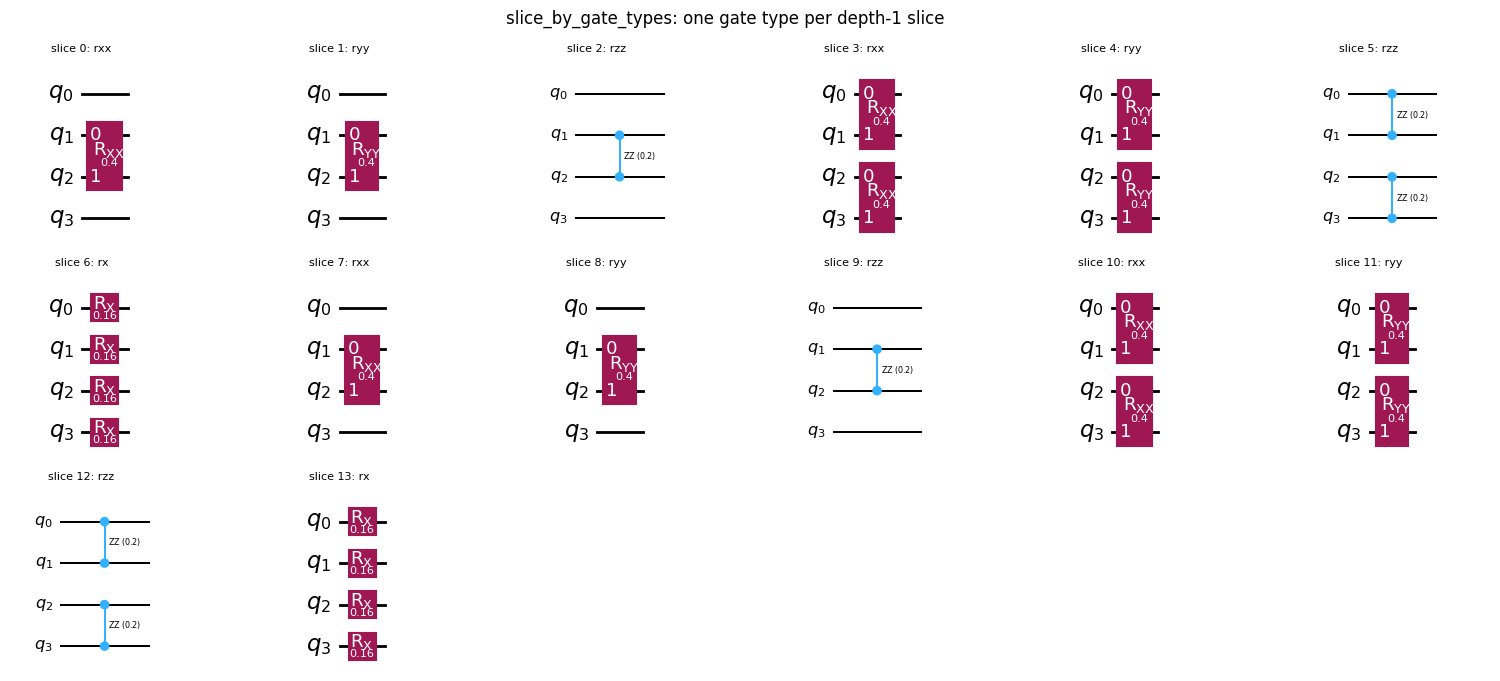

In [13]:
by_type = slice_by_gate_types(circ)
print("slice_by_gate_types:", len(by_type), "slices, all depth 1:", all(s.depth() == 1 for s in by_type))
show_slices(by_type, "slice_by_gate_types: one gate type per depth-1 slice")

coloring: {(0, 1): 1, (1, 2): 0, (2, 3): 1}
slice_by_coloring: 6 slices


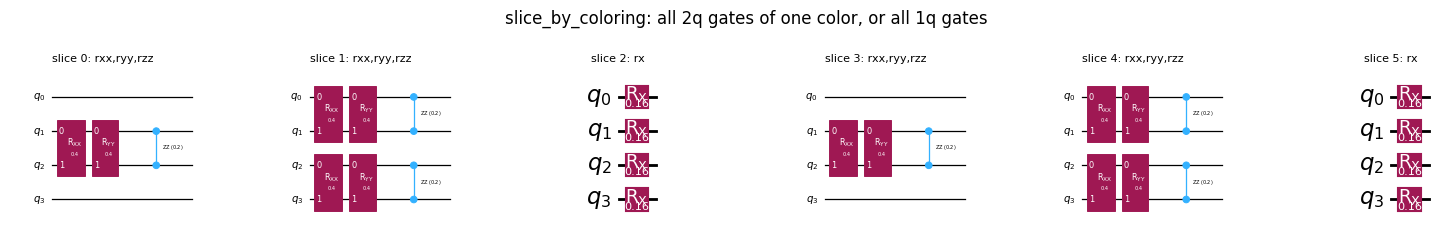

In [14]:
coloring4 = auto_color_edges(undirected(CouplingMap.from_line(4)).edge_list())
print("coloring:", coloring4)
by_color = slice_by_coloring(circ, coloring4)
print("slice_by_coloring:", len(by_color), "slices")
show_slices(by_color, "slice_by_coloring: all 2q gates of one color, or all 1q gates")

`slice_by_coloring` collects two-qubit gates greedily, in order of **increasing color value**. As its docstring states,
this does not guarantee that low-color slices come first. The next cell runs the example from the docstring. `cx(3,4)` (color 1) must
run before `cx(2,3)` (color 0), so the first slice holds color 1.

In [15]:
demo = QuantumCircuit(5); demo.cx(0, 1); demo.cx(3, 4); demo.cx(2, 3)
demo_slices = slice_by_coloring(demo, {(0, 1): 0, (2, 3): 0, (3, 4): 1})
print(combine_slices(demo_slices, include_barriers=True).draw("text"))

           ░      
q_0: ──────░───■──
           ░ ┌─┴─┐
q_1: ──────░─┤ X ├
           ░ └───┘
q_2: ──────░───■──
           ░ ┌─┴─┐
q_3: ──■───░─┤ X ├
     ┌─┴─┐ ░ └───┘
q_4: ┤ X ├─░──────
     └───┘ ░      


slice_by_barriers: 4 slices with ops [{'x': 2}, {'rx': 4, 'rxx': 3, 'ryy': 3, 'rzz': 3}, {'rx': 4, 'rxx': 3, 'ryy': 3, 'rzz': 3}, {'barrier': 1, 'h': 1}]


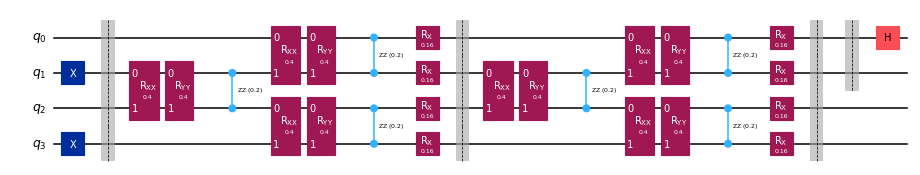

In [16]:
# Barriers: full-width barriers become slice boundaries, partial barriers stay inside the slices.
step = generate_time_evolution_circuit(H4, synthesis=LieTrotter(reps=1), time=0.2)
with_barriers = QuantumCircuit(4)
with_barriers.x([1, 3])
with_barriers.barrier()                 # full barrier -> slice boundary
for _ in range(2):
    with_barriers.compose(step, inplace=True)
    with_barriers.barrier()
with_barriers.barrier([0, 1])           # partial barrier -> kept as an operation
with_barriers.h(0)
by_barrier = slice_by_barriers(with_barriers)
print("slice_by_barriers:", len(by_barrier), "slices with ops", [dict(s.count_ops()) for s in by_barrier])
with_barriers.draw("mpl", fold=-1, scale=0.55)

In [17]:
# combine_slices is the inverse of every slicer: check unitary equivalence
ref = Operator(circ)
for name, sl in {"depth": by_depth, "gate types": by_type, "coloring": by_color}.items():
    print(f"combine_slices(slice_by_{name}) == original:", Operator(combine_slices(sl)).equiv(ref))
print("combine_slices([]) ->", combine_slices([]))

combine_slices(slice_by_depth) == original: True
combine_slices(slice_by_gate types) == original: True
combine_slices(slice_by_coloring) == original: True
combine_slices([]) -> None


### The underlying transpiler passes

The slicing functions are thin wrappers around three `TransformationPass` classes in [`qiskit_addon_utils.slicing.transpiler.passes`](https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.slicing.transpiler.passes.html).
Each pass wraps the blocks it collects into an opaque `slice_op` instruction:

* `CollectOpType(op_name)`: blocks of one gate type;
* `CollectOpSize(size)`: blocks of gates that act on `size` qubits;
* `CollectOpColor(name, edges)`: blocks of two-qubit gates on the given edge set.

These passes can be combined in a custom `PassManager`. The example below puts all single-qubit gates in one slice and all `rzz` gates in another:

In [18]:
from qiskit_addon_utils.slicing.transpiler.passes import CollectOpColor, CollectOpSize, CollectOpType
pm_custom = PassManager([CollectOpSize(1), CollectOpType("rzz"), CollectOpType("rxx"), CollectOpType("ryy")])
wrapped = pm_custom.run(circ)
print("ops after the custom pass manager:", dict(wrapped.count_ops()))
even_bonds = {(0, 1), (2, 3)}
print("CollectOpColor on even bonds:", dict(PassManager([CollectOpColor("even", even_bonds)]).run(circ).count_ops()))

ops after the custom pass manager: {'slice_op': 14}
CollectOpColor on even bonds: {'rx': 8, 'rxx': 2, 'ryy': 2, 'rzz': 2, 'slice_op': 2}


## 5. Input for the other addons

### 5a. Operator backpropagation (OBP)

OBP ([`qiskit-addon-obp` API](https://qiskit.github.io/qiskit-addon-obp/apidocs/qiskit_addon_obp.html)) evolves the observable backwards, in the Heisenberg picture, through the **last** slices of a circuit:
$O\to U_{\text{last}}^\dagger O\,U_{\text{last}}$. It truncates small Pauli terms within an error budget. The quantum computer then
runs only the remaining, shallower circuit, with the new (larger) observable. The slices come directly from
`slice_by_gate_types`, and `combine_slices` rebuilds the reduced circuit.

In [19]:
from qiskit_addon_obp import backpropagate
from qiskit_addon_obp.utils.simplify import OperatorBudget
from qiskit_addon_obp.utils.truncating import setup_budget

t_obp = 1.0
evol = generate_time_evolution_circuit(H, synthesis=SuzukiTrotter(order=2, reps=4), time=t_obp)
slices = [neel] + slice_by_gate_types(evol)            # state preparation is its own slice
obs = ZZ34
print("slices:", len(slices), "| full circuit 2q depth:", depth2q(combine_slices(slices)))

# pass a *list* of observables to get a list back (a single SparsePauliOp in -> a single one out)
budget = setup_budget(max_error_total=0.02, num_slices=len(slices), p_norm=1)
bp_obs, remaining, meta = backpropagate([obs], slices, operator_budget=OperatorBudget(max_qwc_groups=10),
                                        truncation_error_budget=budget)
reduced = combine_slices(remaining)
print(f"backpropagated {meta.num_backpropagated_slices} slices | observable now has {len(bp_obs[0])} terms in "
      f"{len(bp_obs[0].group_commuting(qubit_wise=True))} QWC groups")
print("reduced circuit 2q depth:", depth2q(reduced))

ev_full = estimator.run([(combine_slices(slices), obs)]).result()[0].data.evs
ev_obp = estimator.run([(reduced, bp_obs[0])]).result()[0].data.evs
print(f"<Z3Z4>(t={t_obp}): full Trotter {ev_full:+.5f} | OBP-reduced {ev_obp:+.5f} | exact {exact(t_obp)[1]:+.5f} "
      f"| truncation error bound {meta.accumulated_error(0):.3e}")

slices: 57 | full circuit 2q depth: 48
backpropagated 6 slices | observable now has 16 terms in 9 QWC groups
reduced circuit 2q depth: 42
<Z3Z4>(t=1.0): full Trotter -0.18373 | OBP-reduced -0.18373 | exact -0.21199 | truncation error bound 0.000e+00


### 5b. Multi-product formulas (MPF)

A **static MPF** ([`qiskit_addon_mpf.static` API](https://qiskit.github.io/qiskit-addon-mpf/apidocs/qiskit_addon_mpf.static.html)) runs the same `generate_time_evolution_circuit` with several step counts $k_j$ and combines the results:
$\langle O\rangle_{\text{MPF}}=\sum_j x_j\langle O\rangle_{k_j}$. The coefficients $x_j$ come from `qiskit_addon_mpf.static.setup_static_lse`.
Notebook 06 explains the theory.

MPF coefficients: [ 0.2667 -2.3143  3.0476]


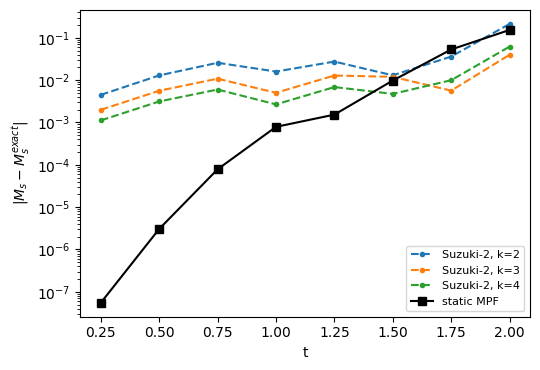

In [20]:
from qiskit_addon_mpf.static import setup_static_lse
mpf_ks = [2, 3, 4]
lse = setup_static_lse(mpf_ks, order=2, symmetric=True)
x_mpf = lse.solve()
print("MPF coefficients:", np.round(x_mpf, 4))

mpf_times = np.linspace(0.25, 2.0, 8)
evs_k = np.array([[r.data.evs for r in estimator.run(
    [(trotter_circuit(t, SuzukiTrotter(order=2, reps=k)), Ms) for t in mpf_times]).result()] for k in mpf_ks]).T
mpf_vals = evs_k @ x_mpf
ex_ms = np.array([exact(t)[0] for t in mpf_times])
plt.figure(figsize=(5.5, 3.8))
for j, k in enumerate(mpf_ks):
    plt.semilogy(mpf_times, np.abs(evs_k[:, j] - ex_ms), "--o", ms=3, label=f"Suzuki-2, k={k}")
plt.semilogy(mpf_times, np.abs(mpf_vals - ex_ms), "k-s", label="static MPF")
plt.xlabel("t"); plt.ylabel(r"$|M_s - M_s^{exact}|$"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

The **dynamic MPF** and its tensor-network evolvers need the product formula as a list of *layers*. One second-order step
from `generate_time_evolution_circuit`, sliced with `slice_by_gate_types`, gives these layers.

* `LayerModel.from_quantum_circuit` ([`quimb_layers` API](https://qiskit.github.io/qiskit-addon-mpf/apidocs/qiskit_addon_mpf.backends.quimb_layers.html)) accepts `rxx/ryy/rzz/xx_plus_yy/rx/ry/rz`.
* Single-qubit layers must be split into odd and even bonds.

Notebook 06 shows the full dynamic-MPF run. Here we only build the layer models.

In [21]:
from qiskit_addon_mpf.backends.quimb_layers import LayerModel
one_step = generate_time_evolution_circuit(H, synthesis=SuzukiTrotter(order=2, reps=1), time=1.0)
layers = slice_by_gate_types(one_step)
models = []
for layer in layers:
    if layer.data[0].operation.num_qubits == 2:
        models.append(LayerModel.from_quantum_circuit(layer))
    else:
        models += [LayerModel.from_quantum_circuit(layer, keep_only_odd=b) for b in (True, False)]
print(len(layers), "layers ->", len(models), "LayerModels:", [",".join(l.count_ops()) for l in layers])

14 layers -> 16 LayerModels: ['rxx', 'ryy', 'rzz', 'rxx', 'ryy', 'rzz', 'rx', 'rx', 'rzz', 'ryy', 'rxx', 'rzz', 'ryy', 'rxx']


### 5c. AQC-Tensor

`qiskit-addon-aqc-tensor` ([`ansatz_generation` API](https://qiskit.github.io/qiskit-addon-aqc-tensor/apidocs/ansatz_generation.html)) compresses a deep Trotter circuit into a shallow parametrized ansatz. Its tutorials build both the
target circuit and the initial ansatz from these utilities: `generate_xyz_hamiltonian` → `generate_time_evolution_circuit` →
`generate_ansatz_from_circuit`.

In [22]:
from qiskit_addon_aqc_tensor.ansatz_generation import generate_ansatz_from_circuit
ansatz, init_params = generate_ansatz_from_circuit(
    generate_time_evolution_circuit(H4, synthesis=SuzukiTrotter(order=2, reps=1), time=0.3), qubits_initially_zero=True)
print("ansatz:", ansatz.num_parameters, "parameters,", dict(ansatz.count_ops()))

ansatz: 44 parameters, {'zxz': 12, 'kak': 4}


## 6. Expectation values from raw bits (`exp_vals`)

Sampler-type primitives, such as `SamplerV2` and the runtime `Executor`, return **raw bits**. The `exp_vals` module converts them into expectation values ([`exp_vals` API](https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.exp_vals.html)):

1. `get_measurement_bases(observables)` groups all Pauli terms into qubit-wise-commuting families. It returns:
   * one measurement basis per family, as a `uint8` array in the samplomatic convention I=0, Z=1, X=2, Y=3 (array index = qubit);
   * a dict `{basis: [part of observable 0, part of observable 1, ...]}`.
2. `executor_expectation_values(bool_array, basis_dict, meas_basis_axis, avg_axis=..., measurement_flips=..., rescale_factors=...,
   pauli_signs=..., postselect_mask=..., gamma_factor=...)` returns $(\text{mean}, \text{variance})$ for each observable.
   `bool_array` has shape `(..., shots, bits)`. Bit 0 is the least significant bit (qubit 0).

We sample the 6-qubit XXZ state at $t=1$ with Aer. The simulation has an **asymmetric readout error**, and we use **measurement twirling**:

* Before each measurement, a random $X$ gate is applied. `measurement_flips` undoes it in classical post-processing.
* Twirling turns any readout error into a symmetric bit-flip channel.
* This channel is a Pauli–Lindblad map with one $X_j$ generator per qubit. `trex_factors` can invert it. This method is TREX ([Error mitigation and suppression techniques](https://quantum.cloud.ibm.com/docs/en/guides/error-mitigation-and-suppression-techniques)).

In [23]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, ReadoutError
from qiskit_aer.primitives import SamplerV2 as AerSampler
from qiskit_addon_utils.exp_vals import executor_expectation_values, get_measurement_bases

device = "GPU" if "GPU" in AerSimulator().available_devices() else "CPU"
nq = 6
H6 = generate_xyz_hamiltonian(CouplingMap.from_line(nq), coupling_constants=(1.0, 1.0, 0.5), ext_magnetic_field=(0.4, 0, 0))
prep6 = QuantumCircuit(nq); prep6.x(range(1, nq, 2))
state6 = prep6.compose(generate_time_evolution_circuit(H6, synthesis=SuzukiTrotter(order=2, reps=4), time=1.0))
Ms6 = SparsePauliOp.from_sparse_list([("Z", [j], (-1) ** j / nq) for j in range(nq)], nq)
observables = [H6, Ms6]
ideal = [float(np.real(Statevector(state6).expectation_value(o))) for o in observables]

bases, basis_dict = get_measurement_bases(observables)
print("bases (uint8, I=0 Z=1 X=2 Y=3):", [b.tolist() for b in bases])
for basis, parts in basis_dict.items():
    print(f"  {basis}: ", [None if p is None else len(p) for p in parts], "terms of [H, M_s]")

bases (uint8, I=0 Z=1 X=2 Y=3): [[3, 3, 3, 3, 3, 3], [2, 2, 2, 2, 2, 2], [1, 1, 1, 1, 1, 1]]
  YYYYYY:  [5, None] terms of [H, M_s]
  XXXXXX:  [11, None] terms of [H, M_s]
  ZZZZZZ:  [5, 6] terms of [H, M_s]


In [24]:
rng = np.random.default_rng(7)
noise_ro = NoiseModel()
noise_ro.add_all_qubit_readout_error(ReadoutError([[0.97, 0.03], [0.08, 0.92]]))   # P(1|0)=3%, P(0|1)=8%
sampler = AerSampler(options=dict(backend_options=dict(noise_model=noise_ro, device=device, seed_simulator=11)))

def basis_rotation(qc, basis):
    for q, p in enumerate(basis):
        if p == 2: qc.h(q)                      # X
        elif p == 3: qc.sdg(q); qc.h(q)         # Y
    return qc

def twirled_runs(state, bases, num_twirls=10, shots=1000):
    flips = rng.integers(0, 2, size=(len(bases), num_twirls, state.num_qubits)).astype(bool)
    circs = []
    for b, basis in enumerate(bases):
        for r in range(num_twirls):
            qc = basis_rotation(state.copy(), basis)
            qc.x([q for q in range(state.num_qubits) if flips[b, r, q]])
            qc.measure_all()
            circs.append(qc)
    res = sampler.run(circs, shots=shots).result()
    bits = np.array([r.data.meas.to_bool_array(order="little") for r in res])
    bits = bits.reshape(len(bases), num_twirls, shots, state.num_qubits)
    return bits, np.broadcast_to(flips[:, :, None, :], bits.shape)

bits, flips = twirled_runs(state6, bases)
print("bool_array shape (bases, twirls, shots, bits):", bits.shape)
raw = executor_expectation_values(bits, basis_dict, 0, avg_axis=1, measurement_flips=flips)
print(f"{'':16s}{'H':>10s}{'M_s':>10s}")
print(f"{'ideal':16s}{ideal[0]:10.4f}{ideal[1]:10.4f}")
print(f"{'twirled, raw':16s}{raw[0][0]:10.4f}{raw[1][0]:10.4f}   (std err {np.sqrt(raw[0][1]):.3f}, {np.sqrt(raw[1][1]):.3f})")

bool_array shape (bases, twirls, shots, bits): (3, 10, 1000, 6)
                         H       M_s
ideal              -2.4444    0.1254
twirled, raw       -1.9296    0.1182   (std err 0.034, 0.004)


**TREX** ([`noise_management` API](https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.noise_management.html)). After twirling, the readout channel on qubit $j$ is $\rho\mapsto(1-p_j)\rho+p_jX_j\rho X_j$.

* As a Pauli–Lindblad map with rate $\lambda_j$, the flip probability is $p_j=(1-e^{-2\lambda_j})/2$.
* A Pauli term on the qubit set $S$ is damped by the fidelity $f_S=\prod_{j\in S}e^{-2\lambda_j}$. Its estimate must be multiplied by $1/f_S$.

We **learn** $f_j$ from twirled calibration circuits that prepare $|0\cdots0\rangle$. We then build the `PauliLindbladMap`, and
`trex_factors` produces the `rescale_factors` for every term of every observable in every basis.

In [25]:
from qiskit_addon_utils.noise_management import trex_factors

cal_bits, cal_flips = twirled_runs(QuantumCircuit(nq), [np.ones(nq, dtype=np.uint8)], num_twirls=20, shots=1000)
z_ops = [SparsePauliOp.from_sparse_list([("Z", [j], 1.0)], nq) for j in range(nq)]
cal = executor_expectation_values(cal_bits, (z_ops, ["Z" * nq]), 0, avg_axis=1,
                                  measurement_flips=cal_flips)
f = np.array([m for m, _ in cal])
lam = -0.5 * np.log(f)
print("learned <Z_j> on |0>:", np.round(f, 4), "(expected 1 - (0.03+0.08) = 0.89)")
meas_noise = PauliLindbladMap.from_sparse_list([("X", [j], lam[j]) for j in range(nq)], nq)
print(meas_noise)

# Note (v0.4.0): with rescale_factors, executor_expectation_values does np.reshape on the nested list of factors,
# which fails when the observables in one basis have *different* numbers of terms (ragged list).
# Work-around: process one observable at a time.
trex = []
for i in range(len(observables)):
    bd_i = {basis: [parts[i]] for basis, parts in basis_dict.items()}
    trex += executor_expectation_values(bits, bd_i, 0, avg_axis=1, measurement_flips=flips,
                                        rescale_factors=trex_factors(meas_noise, bd_i))
print(f"\n{'':16s}{'H':>10s}{'M_s':>10s}")
for name, vals in [("ideal", ideal), ("twirled, raw", [m for m, _ in raw]), ("twirled + TREX", [m for m, _ in trex])]:
    print(f"{name:16s}{vals[0]:10.4f}{vals[1]:10.4f}")

learned <Z_j> on |0>: [0.8696 0.9168 0.8897 0.8632 0.8907 0.8627] (expected 1 - (0.03+0.08) = 0.89)
<PauliLindbladMap with 6 terms on 6 qubits: (0.06986097158756865)L(X_0) + (0.04343296651083099)L(X_1) + (0.058435475865707666)L(X_2) + (0.0735544325191061)L(X_3) + (0.0578738042721566)L(X_4) + (0.07384413644980196)L(X_5)>

                         H       M_s
ideal              -2.4444    0.1254
twirled, raw       -1.9296    0.1182
twirled + TREX     -2.4950    0.1324


The calibration call passes `basis_mapping` in its second accepted form, a tuple `(observables, measurement_bases)`. The
function then assigns each term to the first basis that qubit-wise commutes with it. TREX removes the readout bias. The remaining
difference from the ideal values is shot noise.

### Helpers to re-index observables

After transpilation, an observable must refer to **physical** qubits. Samplomatic boxes use a **canonical** order of
the qubits inside a box instead. Three helper functions convert between these index spaces:

In [26]:
from qiskit_addon_utils.exp_vals import (map_observable_isa_to_canonical, map_observable_isa_to_virtual,
                                         map_observable_virtual_to_canonical)
isa6 = generate_preset_pass_manager(optimization_level=1, backend=backend, initial_layout=[20, 21, 22, 23, 24, 25],
                                    seed_transpiler=1).run(state6)
layout = isa6.layout.final_index_layout()                      # virtual qubit i -> physical qubit layout[i]
obs_virtual = SparsePauliOp.from_sparse_list([("ZZ", [0, 1], 1.0), ("X", [5], 0.5)], nq)
obs_isa = obs_virtual.apply_layout(isa6.layout)                # 127-qubit observable
print("layout:", layout, "| ISA observable:", obs_isa.to_sparse_list())
print("isa -> virtual:", map_observable_isa_to_virtual(obs_isa, layout).to_sparse_list())
canonical = sorted(layout)                                     # e.g. box qubits in increasing physical order
print("isa -> canonical:", map_observable_isa_to_canonical(obs_isa, canonical).to_sparse_list())
print("virtual -> canonical:", map_observable_virtual_to_canonical(obs_virtual, layout, canonical).to_sparse_list())

layout: [20, 21, 22, 23, 24, 25] | ISA observable: [('ZZ', [20, 21], np.complex128(1+0j)), ('X', [25], np.complex128(0.5+0j))]
isa -> virtual: [('ZZ', [0, 1], np.complex128(1+0j)), ('X', [5], np.complex128(0.5+0j))]
isa -> canonical: [('ZZ', [0, 1], np.complex128(1+0j)), ('X', [5], np.complex128(0.5+0j))]
virtual -> canonical: [('ZZ', [0, 1], np.complex128(1+0j)), ('X', [5], np.complex128(0.5+0j))]


## 7. Noise management

### 7a. Pauli–Lindblad maps and the PEC overhead $\gamma$

The learned noise of a layer of gates (a *box*) is usually modeled as a sparse **Pauli–Lindblad map**
$\Lambda(\rho)=\exp\!\big[\sum_k\lambda_k(P_k\rho P_k-\rho)\big]$. It has one rate $\lambda_k\ge0$ per generator $P_k$
(class [`qiskit.quantum_info.PauliLindbladMap`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.PauliLindbladMap)).

* The inverse map has rates $-\lambda_k$. It is not a physical channel.
* The inverse can still be sampled as a quasi-probability distribution with total weight

$$\gamma=\prod_k e^{2\lambda_k}\qquad(\text{per box; for the whole circuit, multiply over boxes}).$$

* Probabilistic error cancellation (PEC, see [Error mitigation and suppression techniques](https://quantum.cloud.ibm.com/docs/en/guides/error-mitigation-and-suppression-techniques)) needs about $\gamma^2$ times more shots for the same precision.

`gamma_from_noisy_boxes(noise_models, box_id_to_noise_id, noise_scales_each_box=None)` ([`noise_management` API](https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.noise_management.html)) returns $\gamma$ for the circuit. The optional
per-generator scales multiply the rates before inversion. A scale $s$ cancels the fraction $s$ of each rate, as in partial PEC
and noise-scaling methods.

even_layer: 43 generators, sum of rates 0.0249, gamma(inverse) = 1.0512 = exp(2*sum) = 1.0512
odd_layer: 43 generators, sum of rates 0.0389, gamma(inverse) = 1.0809 = exp(2*sum) = 1.0809


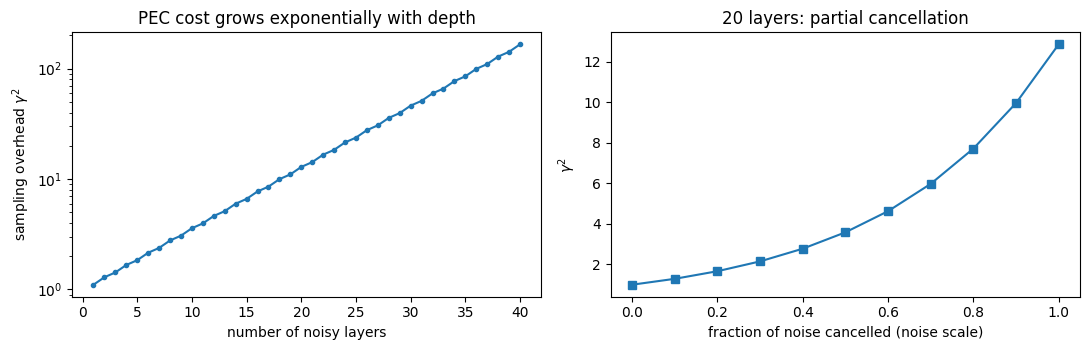

In [27]:
from qiskit_addon_utils.noise_management import gamma_from_noisy_boxes
rng = np.random.default_rng(3)
nb = 6
def learned_like_noise(n, scale):
    terms = [(p, [j], scale * rng.uniform(0.5, 1.5)) for j in range(n) for p in "XYZ"]
    terms += [(p, [j, j + 1], 0.3 * scale * rng.uniform(0.5, 1.5)) for j in range(n - 1)
              for p in ["XX", "YY", "ZZ", "XZ", "ZX"]]
    return PauliLindbladMap.from_sparse_list(terms, n)

noise_models = {"even_layer": learned_like_noise(nb, 1e-3), "odd_layer": learned_like_noise(nb, 1.5e-3)}
for k, plm in noise_models.items():
    print(f"{k}: {plm.num_terms} generators, sum of rates {plm.rates.sum():.4f}, "
          f"gamma(inverse) = {plm.inverse().gamma():.4f} = exp(2*sum) = {np.exp(2 * plm.rates.sum()):.4f}")

layers_range = np.arange(1, 41)
gam = [gamma_from_noisy_boxes(noise_models, {f"box{i}": ("even_layer" if i % 2 == 0 else "odd_layer")
                                             for i in range(L)}) for L in layers_range]
L = 20
box_map = {f"box{i}": ("even_layer" if i % 2 == 0 else "odd_layer") for i in range(L)}
scales = np.linspace(0, 1, 11)
gam_s = [gamma_from_noisy_boxes(noise_models, box_map,
         {b: np.full(noise_models[n].num_terms, s) for b, n in box_map.items()}) for s in scales]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].semilogy(layers_range, np.array(gam) ** 2, "o-", ms=3); ax[0].set_xlabel("number of noisy layers")
ax[0].set_ylabel(r"sampling overhead $\gamma^2$"); ax[0].set_title("PEC cost grows exponentially with depth")
ax[1].plot(scales, np.array(gam_s) ** 2, "s-"); ax[1].set_xlabel("fraction of noise cancelled (noise scale)")
ax[1].set_ylabel(r"$\gamma^2$"); ax[1].set_title(f"{L} layers: partial cancellation")
plt.tight_layout(); plt.show()

### 7b. A small end-to-end PEC experiment

We emulate PEC on 4 qubits with three identical noisy boxes. For each of $R$ circuit randomizations:

1. The **noise** is applied exactly as a random Pauli: after every box we insert a Pauli sampled from $\Lambda$ (`PauliLindbladMap.sample`).
2. The **inverse noise** is sampled with `parity_sample` on $\Lambda^{-1}$. It returns a Pauli and a sign bit for each box
   (`True` means a factor $-1$). The Pauli is inserted into the circuit as well.

`executor_expectation_values(..., pauli_signs=signs, gamma_factor=γ)` then applies the sign of each randomization (XOR), averages over
the randomization axis and rescales by $\gamma$. Without `gamma_factor`, the function should estimate $\gamma$ from the signs.
In version 0.4.0 this fails together with `avg_axis` (see the notes in Section 8). We therefore compute the empirical estimate ourselves.

In [28]:
nP, n_boxes, R, shots_pec = 4, 3, 2000, 16   # many randomizations, few shots each
box = QuantumCircuit(nP)
box.rx(0.4, range(nP)); box.rzz(0.7, 0, 1); box.rzz(0.7, 2, 3); box.rzz(0.7, 1, 2)
pec_noise = learned_like_noise(nP, 0.008)        # strong noise so the bias is visible
pec_obs = [SparsePauliOp.from_sparse_list([("Z", [j], 1 / nP) for j in range(nP)], nP),
           SparsePauliOp.from_sparse_list([("ZZ", [1, 2], 1.0)], nP)]
ideal_circ = QuantumCircuit(nP)
for _ in range(n_boxes): ideal_circ.compose(box, inplace=True)
ideal_pec = [float(np.real(Statevector(ideal_circ).expectation_value(o))) for o in pec_obs]

def pauli_layer(qsp):
    qc = QuantumCircuit(nP); qc.append(qsp.to_pauli().to_instruction(), range(nP)); return qc

inv = pec_noise.inverse()
noisy_circs, pec_circs, signs = [], [], np.zeros((R, n_boxes), dtype=bool)
noise_samples = [pec_noise.sample(R, seed=100 + b) for b in range(n_boxes)]
inv_samples = [inv.parity_sample(R, seed=200 + b) for b in range(n_boxes)]
for r in range(R):
    qn, qp = QuantumCircuit(nP), QuantumCircuit(nP)
    for b in range(n_boxes):
        err = pauli_layer(noise_samples[b][r])
        qn.compose(box, inplace=True); qn.compose(err, inplace=True)
        qp.compose(box, inplace=True); qp.compose(err, inplace=True)
        qp.compose(pauli_layer(inv_samples[b][1][r]), inplace=True)
        signs[r, b] = inv_samples[b][0][r]
    qn.measure_all(); qp.measure_all()
    noisy_circs.append(qn); pec_circs.append(qp)

# thousands of tiny circuits: the CPU (2 threads) is faster than GPU launch overhead here
ideal_sampler = AerSampler(options=dict(backend_options=dict(device="CPU", max_parallel_threads=2, seed_simulator=5)))
def run_bits(circs):
    return np.array([r.data.meas.to_bool_array(order="little")
                     for r in ideal_sampler.run(circs, shots=shots_pec).result()])
bits_noisy, bits_pec = run_bits(noisy_circs), run_bits(pec_circs)     # shape (R, shots, bits)
z_basis = ({Pauli("Z" * nP): pec_obs})                                 # one basis -> meas_basis_axis=None

gamma_pec = gamma_from_noisy_boxes({"L": pec_noise}, {f"b{i}": "L" for i in range(n_boxes)})
unmit = executor_expectation_values(bits_noisy, z_basis, avg_axis=0)
pec_g = executor_expectation_values(bits_pec, z_basis, avg_axis=0, pauli_signs=signs, gamma_factor=gamma_pec)
# Note (v0.4.0): leaving gamma_factor=None (empirical gamma) together with avg_axis raises a broadcasting
# ValueError. Work-around: compute the same empirical estimate 1/(1 - 2*P(sign=-1)) by hand and pass it as a float.
gamma_emp = float(1 / (1 - 2 * np.mean(signs.sum(axis=1) % 2)))
pec_e = executor_expectation_values(bits_pec, z_basis, avg_axis=0, pauli_signs=signs, gamma_factor=gamma_emp)
print(f"gamma = {gamma_pec:.3f} (overhead gamma^2 = {gamma_pec**2:.2f}), empirical gamma = {gamma_emp:.3f}; "
      f"fraction of negative randomizations = {np.mean(signs.sum(1) % 2):.3f}")
print(f"{'':22s}{'<M_z>':>10s}{'<Z1Z2>':>10s}")
print(f"{'ideal':22s}{ideal_pec[0]:10.4f}{ideal_pec[1]:10.4f}")
# The returned variance treats every shot as independent. With PEC the randomizations dominate the spread,
# so we also estimate the error bar from 20 independent batches of randomizations.
def batch_err(bits, sgn=None, gamma=None, nbatch=20):
    vals = []
    for idx in np.array_split(np.arange(R), nbatch):
        kw = {} if sgn is None else dict(pauli_signs=sgn[idx], gamma_factor=gamma)
        vals.append([m for m, _ in executor_expectation_values(bits[idx], z_basis, avg_axis=0, **kw)])
    return np.std(vals, axis=0, ddof=1) / np.sqrt(nbatch)
errs_b = {"noisy (unmitigated)": batch_err(bits_noisy), "PEC, gamma given": batch_err(bits_pec, signs, gamma_pec),
          "PEC, gamma estimated": batch_err(bits_pec, signs, gamma_emp)}
print(f"{'':22s}{'':20s}{'reported std err':>18s}{'batch std err':>18s}")
for name, v in [("noisy (unmitigated)", unmit), ("PEC, gamma given", pec_g), ("PEC, gamma estimated", pec_e)]:
    print(f"{name:22s}{v[0][0]:10.4f}{v[1][0]:10.4f}   {np.sqrt(v[0][1]):7.4f},{np.sqrt(v[1][1]):7.4f}"
          f"   {errs_b[name][0]:7.4f},{errs_b[name][1]:7.4f}")

gamma = 2.159 (overhead gamma^2 = 4.66), empirical gamma = 2.193; fraction of negative randomizations = 0.272
                           <M_z>    <Z1Z2>
ideal                     0.6677    0.7421
                                            reported std err     batch std err
noisy (unmitigated)       0.5670    0.5475    0.0023, 0.0047    0.0037, 0.0092
PEC, gamma given          0.6766    0.7581    0.0057, 0.0113    0.0202, 0.0251
PEC, gamma estimated      0.6872    0.7700    0.0058, 0.0115    0.0205, 0.0255


PEC removes the bias of the unmitigated estimate, within the error bars. The cost is much larger error bars, because the shot overhead scales as $\gamma^2$.

* The variance from `executor_expectation_values` treats all `R × shots` shots as independent.
* PEC here uses few shots per randomization, so the spread between randomizations dominates. The correct error bar is the batch estimate in the last column.

In a real workflow, the Pauli signs come from the PEC randomization metadata, and the noise models come from a noise-learning
experiment. Here we generate both locally.

### 7c. Post-selection with bit-flip checks

Post-selection with **bit-flip checks** discards shots in which a qubit was found in the wrong state (how-to: [Postselection using bit-flip checks](https://qiskit.github.io/qiskit-addon-utils/how_tos/postselection_with_bit_flip_checks.html); [`bit_flip_checks` API](https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.noise_management.bit_flip_checks.html), [passes API](https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.noise_management.bit_flip_checks.passes.html)):

| tool | what it does |
|---|---|
| `AddPostCircuitBitFlipChecks` | After the final measurement, flip the qubit with a slow X pulse (`xslow`, or 20 × `rx(π/20)`) and measure again into register `<name>_ps`. A healthy qubit returns the **opposite** bit. A readout error or leakage breaks this. |
| `AddPreCircuitBitFlipChecks` | At the start, apply a slow X and an X, then measure into `<name>_pre`. The result must be 0. |
| `AddSpectatorPre/PostCircuitBitFlipChecks(coupling_map)` | The same checks on idle **neighbour** qubits of the active qubits (registers `spec`, `spec_pre`). |
| `bit_flip_checks.PostSelector.from_circuit(circ, coupling_map).compute_mask(result, strategy, mode=...)` | Returns a boolean keep-mask. `strategy="node"` discards a shot if any check failed. `"edge"` discards it only if both ends of a coupled pair failed. `mode` is `"post"`, `"pre"` or `"both"`. |

The default `xslow` gate is a device-native pulse. Simulators cannot run it, so we use `x_pulse_type="rx"`. The circuit is a 4-qubit mirror circuit
(ideal outcome all zeros, so $\langle Z\rangle=1$) on 5 qubits of a line. Qubit 4 is the spectator.

classical registers: [('meas', 4), ('meas_pre', 4), ('spec_pre', 1), ('meas_ps', 4), ('spec', 1), ('spec_ps', 1)]


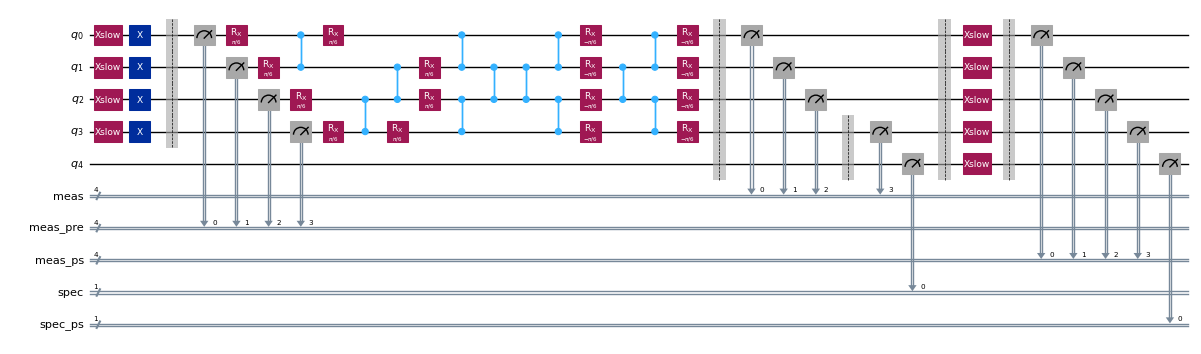

In [29]:
from qiskit_addon_utils.noise_management.bit_flip_checks import PostSelector
from qiskit_addon_utils.noise_management.bit_flip_checks.passes import (
    AddPostCircuitBitFlipChecks, AddPreCircuitBitFlipChecks,
    AddSpectatorPostCircuitBitFlipChecks, AddSpectatorPreCircuitBitFlipChecks)
from qiskit.circuit import ClassicalRegister

cm5 = CouplingMap.from_line(5)
mirror = QuantumCircuit(5)
for _ in range(2):
    mirror.rx(np.pi / 6, range(4)); mirror.cz(0, 1); mirror.cz(2, 3); mirror.cz(1, 2)
mirror = mirror.compose(mirror.inverse())
meas = ClassicalRegister(4, "meas"); mirror.add_register(meas)
mirror.barrier(); mirror.measure(range(4), meas)

checked = PassManager([
    AddPreCircuitBitFlipChecks(x_pulse_type="rx"),
    AddSpectatorPreCircuitBitFlipChecks(cm5, x_pulse_type="rx"),
    AddPostCircuitBitFlipChecks(x_pulse_type="rx"),
    AddSpectatorPostCircuitBitFlipChecks(cm5, x_pulse_type="rx"),
]).run(mirror)
print("classical registers:", [(c.name, c.size) for c in checked.cregs])
PassManager([AddPreCircuitBitFlipChecks(), AddPostCircuitBitFlipChecks(),
             AddSpectatorPostCircuitBitFlipChecks(cm5)]).run(mirror).draw("mpl", fold=-1, scale=0.5)

The drawing above uses the default `xslow` pulse, which keeps it compact. The simulated circuit uses the `rx` chain. The noise model
has three parts:

* depolarizing gate errors;
* asymmetric readout errors;
* an *amplitude-damping* error on the slow pulses. It models $T_1$ decay and leakage-like loss.

In [30]:
from qiskit_aer.noise import amplitude_damping_error, depolarizing_error
nm = NoiseModel()
nm.add_all_qubit_quantum_error(depolarizing_error(0.004, 1).compose(amplitude_damping_error(0.004)), ["rx"])
nm.add_all_qubit_quantum_error(depolarizing_error(0.004, 1), ["x", "sx"])
nm.add_all_qubit_quantum_error(depolarizing_error(0.02, 2), ["cz"])
nm.add_all_qubit_readout_error(ReadoutError([[0.98, 0.02], [0.06, 0.94]]))
# mid-circuit measurements + noise -> shot-by-shot simulation; for 5 qubits the CPU is much faster than the GPU
ps_sampler = AerSampler(options=dict(backend_options=dict(noise_model=nm, device="CPU", max_parallel_threads=2, seed_simulator=3)))
res = ps_sampler.run([checked], shots=4000).result()[0]
result = {c.name: getattr(res.data, c.name).to_bool_array(order="little") for c in checked.cregs}

selector = PostSelector.from_circuit(checked, cm5)
mz = lambda b, m=None: (1 - 2 * (b if m is None else b[m]).astype(int)).mean()
print(f"{'selection':24s}{'<Z>':>8s}{'kept':>8s}   (ideal <Z> = 1)")
print(f"{'none':24s}{mz(result['meas']):8.4f}{1.0:8.3f}")
for mode in ("pre", "post", "both"):
    for strat in ("node", "edge"):
        m = selector.compute_mask(result, strat, mode=mode)
        print(f"{mode + ' / ' + strat:24s}{mz(result['meas'], m):8.4f}{m.mean():8.3f}")

selection                    <Z>    kept   (ideal <Z> = 1)
none                      0.7150   1.000
pre / node                0.8218   0.638
pre / edge                0.7288   0.973
post / node               0.7288   0.476
post / edge               0.7185   0.930
both / node               0.8487   0.303
both / edge               0.7329   0.904


Post-selection moves $\langle Z\rangle$ toward 1 and discards a fraction of the shots. The `edge` strategy keeps many more shots
than `node`, but it removes much less of the bias. `compute_mask` expects a `{creg_name: bool ndarray}`
dictionary. Above, we build it from the Aer `SamplerV2` result. The mask can be passed as `postselect_mask` to `executor_expectation_values`:

In [31]:
keep = selector.compute_mask(result, "node", mode="both")
z_obs = [SparsePauliOp.from_sparse_list([("Z", [j], 0.25) for j in range(4)], 4)]
(mean_all, _), = executor_expectation_values(result["meas"], {Pauli("ZZZZ"): z_obs})
(mean_ps, var_ps), = executor_expectation_values(result["meas"], {Pauli("ZZZZ"): z_obs}, postselect_mask=keep)
print(f"<M_z> all shots: {mean_all:.4f} | post-selected: {mean_ps:.4f} +/- {np.sqrt(var_ps):.4f}")

<M_z> all shots: 0.7150 | post-selected: 0.8487 +/- 0.0076


**Older interface.** `qiskit_addon_utils.noise_management.PostSelector` (exported at the top level of `noise_management`) and the passes
[`noise_management.post_selection.transpiler.passes`](https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.noise_management.post_selection.transpiler.passes.html)`.AddPostSelectionMeasures` / `AddSpectatorMeasures` are the earlier version of the
same idea. They support post checks only and have no `mode` argument. The two `PostSelector` classes have the same name but come from
different modules. Use the `bit_flip_checks` version for pre and post checks.

In [32]:
from qiskit_addon_utils.noise_management import PostSelector as PostSelectorPostOnly
from qiskit_addon_utils.noise_management.post_selection.transpiler.passes import AddPostSelectionMeasures, AddSpectatorMeasures
old = PassManager([AddSpectatorMeasures(cm5), AddPostSelectionMeasures(x_pulse_type="rx")]).run(mirror)
print("registers:", [(c.name, c.size) for c in old.cregs])
r_old = ps_sampler.run([old], shots=4000).result()[0]
res_old = {c.name: getattr(r_old.data, c.name).to_bool_array(order="little") for c in old.cregs}
m_old = PostSelectorPostOnly.from_circuit(old, cm5).compute_mask(res_old, "node")
print(f"post-only node selection: <Z> = {mz(res_old['meas'], m_old):.4f}, kept {m_old.mean():.3f}")

registers: [('meas', 4), ('spec', 1), ('meas_ps', 4), ('spec_ps', 1)]
post-only node selection: <Z> = 0.8475, kept 0.470


## 8. Summary, notes on the installed version, and references

* **Problem generators.** `generate_xyz_hamiltonian(coupling, coupling_constants=(Jx,Jy,Jz), ext_magnetic_field=(hx,hy,hz),
  pauli_order_strategy=..., coloring=...)` accepts any coupling graph. It ignores direction and duplicate edges.
  `generate_time_evolution_circuit(H, synthesis=..., time=t)` returns a **decomposed** Trotter circuit. Its simulation shows the true
  Trotter error. The convergence orders 1, 2 and 4 agree with exact evolution (`StatevectorEstimator`).
* **Coloring.** The number of edge colors sets the two-qubit depth of each Trotter step. `auto_color_edges` is greedy, and
  its result depends on the edge list. A König (bipartite) coloring from rustworkx, passed with `coloring=`, is optimal on heavy-hex lattices.
* **Slicing.** `slice_by_depth / gate_types / coloring / barriers` and `combine_slices` produce the slices for OBP,
  the layers for MPF layer models and the per-layer structure for noise learning. The `CollectOp*` passes allow custom slicers.
* **Other addons.** OBP: `backpropagate(obs, slices, ...)` → `combine_slices(remaining)`. Static MPF: the same circuit generator with
  several `reps`. Dynamic MPF: `LayerModel.from_quantum_circuit` on `slice_by_gate_types` of one step. AQC-Tensor: `generate_ansatz_from_circuit`.
* **Expectation values and noise.** `get_measurement_bases` and `executor_expectation_values` turn raw bits into expectation values. They support
  measurement twirling, TREX (`trex_factors`), PEC signs and $\gamma$ (`gamma_from_noisy_boxes`), and post-selection masks
  (`bit_flip_checks`).

### Notes on the installed version (v0.4.0)

* `generate_xyz_hamiltonian` applies no prefactor (no $-\tfrac12$). It drops zero couplings without a warning, so
  `H.size` depends on which constants are non-zero.
* `generate_time_evolution_circuit` uses **one** Lie–Trotter step if `synthesis` is omitted. It decomposes exactly one level.
* `auto_color_edges` does not merge `(a, b)` and `(b, a)`. With `CouplingMap.get_edges()` of a bidirectional map, each bond
  gets two colors (6 instead of 3 on heavy-hex). Passing that coloring to `generate_xyz_hamiltonian` **counts every bond twice**.
  Workaround: pass `cmap.graph.to_undirected(multigraph=False).edge_list()`, or use a König coloring from `rx.graph_bipartite_edge_color`.
* `slice_by_coloring` processes colors in increasing order, but the colors do not always appear left to right. `slice_by_gate_types`
  can order disjoint slices arbitrarily. `combine_slices([])` returns `None`, not an empty circuit.
* `executor_expectation_values` takes `bool_array` and `basis_mapping` as **positional-only** arguments.
  * It returns a plain list of `(mean, variance)` tuples (nested lists for batched shapes).
  * The variances ignore covariances between terms. They also treat all shots as independent, which underestimates PEC error bars when there are few shots per randomization.
  * `basis_mapping` can be a dict `{basis: [obs parts]}` or a tuple `(observables, bases)`.
* **Bug:** `executor_expectation_values(..., rescale_factors=...)` fails with `ValueError: inhomogeneous shape` when the observables
  in one basis have different numbers of terms (the nested list of factors is ragged). Workaround: call it once per observable (Section 6).
* **Bug:** `executor_expectation_values(..., pauli_signs=..., gamma_factor=None, avg_axis=...)` (empirical $\gamma$) raises
  `ValueError: non-broadcastable output operand`. Workaround: pass `gamma_factor` explicitly, either from `gamma_from_noisy_boxes` or as
  `1/(1-2*mean(net_sign))` (Section 7b).
* `qiskit_addon_obp.backpropagate` returns a single `SparsePauliOp` for a single observable, and a list for a list.
  Indexing `[0]` on a single-observable result returns the first **Pauli term** without an error. Workaround: pass a list.
* `get_measurement_bases` returns bases as `uint8` arrays in *qubit order* (I=0, Z=1, X=2, Y=3). This order is the reverse of the Pauli label.
* `PauliLindbladMap.signed_sample` uses `True = +1`, while `parity_sample` (preferred) uses `True = -1`. The `pauli_signs` argument of
  `executor_expectation_values` follows the `parity_sample` convention.
* There are two `PostSelector` classes: `noise_management.PostSelector` (post checks only) and
  `noise_management.bit_flip_checks.PostSelector` (pre, post and spectator checks, with a `mode` argument). Simulators cannot run the `xslow` pulse.
  Workaround: use `x_pulse_type="rx"`.

### References

1. How-to: *Use edge coloring to reduce the depth of quantum circuits*. https://qiskit.github.io/qiskit-addon-utils/how_tos/color_device_edges_to_improve_depth.html
2. How-to: *Slicing circuits using `qiskit_addon_utils.slicing`*. https://qiskit.github.io/qiskit-addon-utils/how_tos/create_circuit_slices.html
3. How-to: *Postselection using bit-flip checks*. https://qiskit.github.io/qiskit-addon-utils/how_tos/postselection_with_bit_flip_checks.html
4. API: `qiskit_addon_utils.problem_generators`. https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.problem_generators.html
5. API: `qiskit_addon_utils.coloring`. https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.coloring.html
6. API: `qiskit_addon_utils.slicing`. https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.slicing.html
7. API: `qiskit_addon_utils.slicing.transpiler.passes`. https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.slicing.transpiler.passes.html
8. API: `qiskit_addon_utils.exp_vals`. https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.exp_vals.html
9. API: `qiskit_addon_utils.noise_management`. https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.noise_management.html
10. API: `qiskit_addon_utils.noise_management.bit_flip_checks`. https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.noise_management.bit_flip_checks.html
11. API: `qiskit_addon_utils.noise_management.bit_flip_checks.passes`. https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.noise_management.bit_flip_checks.passes.html
12. API: `qiskit_addon_utils.noise_management.post_selection.transpiler.passes`. https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.noise_management.post_selection.transpiler.passes.html
13. IBM Quantum guide: *Error mitigation and suppression techniques* (TREX, PEC). https://quantum.cloud.ibm.com/docs/en/guides/error-mitigation-and-suppression-techniques
14. Qiskit API: `PauliLindbladMap`. https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.PauliLindbladMap
15. API: `qiskit_addon_obp`. https://qiskit.github.io/qiskit-addon-obp/apidocs/qiskit_addon_obp.html
16. API: `qiskit_addon_mpf.static` (see also notebook 06). https://qiskit.github.io/qiskit-addon-mpf/apidocs/qiskit_addon_mpf.static.html
17. API: `qiskit_addon_mpf.backends.quimb_layers`. https://qiskit.github.io/qiskit-addon-mpf/apidocs/qiskit_addon_mpf.backends.quimb_layers.html
18. API: `qiskit_addon_aqc_tensor.ansatz_generation` (see also notebook 05). https://qiskit.github.io/qiskit-addon-aqc-tensor/apidocs/ansatz_generation.html

In [33]:
print(f"notebook runtime: {_time.time() - _t_notebook:.1f} s")

notebook runtime: 17.8 s
